<div style="background:#0B2545;color:white;padding:18px 22px;border-radius:8px">
<div style="font-size:12px;letter-spacing:2px;opacity:.8">DATABANK ACADEMY · PROGRAMA EJECUTIVO EN GESTIÓN INTEGRAL DEL RIESGO DE CRÉDITO MINORISTA</div>
<div style="font-size:24px;font-weight:700;margin-top:6px">Módulo 3 · Sesión 2: Multicolinealidad, regularización, selección de variables y métodos avanzados</div>
<div style="font-size:14px;margin-top:4px;opacity:.9">Laboratorio: VIF y estabilidad, trayectorias L1/L2/elastic net, stepwise AIC/BIC, stability selection, splines e interacciones</div>
</div>

## Objetivos de la sesión (2 horas)

1. Diagnosticar **multicolinealidad** (correlación, VIF, número de condición) y ver su efecto en la estabilidad de los coeficientes.
2. Aplicar **regularización L1, L2 y elastic net**: trayectorias de coeficientes y selección de la penalización por validación cruzada.
3. Comparar métodos de **selección de variables**: filtros (IV, correlación), *wrappers* (stepwise con AIC/BIC), embebidos (L1), **stability selection** e importancia por permutación.
4. Aplicar **métodos avanzados** para modelos logísticos: splines para no linealidades, interacciones y modelos segmentados.

| Bloque | Tiempo | Contenido |
|---|---|---|
| 1 | 25 min | Multicolinealidad: diagnóstico y consecuencias |
| 2 | 25 min | Regularización L1, L2 y elastic net |
| 3 | 35 min | Selección de variables: cinco enfoques |
| 4 | 25 min | Métodos avanzados: splines, interacciones, segmentación |
| 5 | 10 min | Ejercicios |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "font.size": 11})
AZUL, ROJO, VERDE, GRIS, ORO = "#0B2545", "#C8102E", "#2E8B57", "#8D99AE", "#E0A100"
DATA = Path("../datos")

import warnings; warnings.filterwarnings("ignore")
import statsmodels.api as sm, sklearn
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, SplineTransformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, log_loss
from sklearn.inspection import permutation_importance

NUEVA_API = tuple(int(v) for v in sklearn.__version__.split(".")[:2]) >= (1, 8)
def logit_pen(C=1.0, l1_ratio=0.0, **kw):
    """Logística penalizada compatible con scikit-learn antiguo (penalty=) y >= 1.8 (l1_ratio=)."""
    if NUEVA_API:
        return LogisticRegression(C=C, l1_ratio=l1_ratio, solver="saga", max_iter=5000, **kw)
    pen = "l2" if l1_ratio == 0 else "l1" if l1_ratio == 1 else "elasticnet"
    return LogisticRegression(C=C, penalty=pen, l1_ratio=l1_ratio if pen == "elasticnet" else None, solver="saga", max_iter=5000, **kw)

app = pd.read_csv(DATA / "hc_application_sintetico.csv").drop_duplicates()
app["EDAD"] = -app.DAYS_BIRTH / 365.25
app["ANTIG"] = np.where(app.DAYS_EMPLOYED == 365243, 0, -app.DAYS_EMPLOYED / 365.25)
app["PENSIONISTA"] = (app.DAYS_EMPLOYED == 365243).astype(int)
app["RCI"] = app.AMT_ANNUITY / (app.AMT_INCOME_TOTAL / 12)
app["LTI"] = app.AMT_CREDIT / app.AMT_INCOME_TOTAL
app["LOG_INGRESO"] = np.log(app.AMT_INCOME_TOTAL); app["LOG_CREDITO"] = np.log(app.AMT_CREDIT)
app["LOG_CUOTA"] = np.log(app.AMT_ANNUITY); app["LOG_BIEN"] = np.log(app.AMT_GOODS_PRICE.fillna(app.AMT_CREDIT))
for c in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]:
    app[c + "_F"] = app[c].fillna(app[c].median()); app[c + "_NA"] = app[c].isna().astype(int)
app["EXT_PROM"] = app[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]].mean(axis=1).fillna(0.5)
app["HOMBRE"] = (app.CODE_GENDER == "M").astype(int); app["SIN_AUTO"] = (app.FLAG_OWN_CAR == "N").astype(int)
app["EDU_SUP"] = (app.NAME_EDUCATION_TYPE == "Higher education").astype(int)
app["DIGITAL"] = (app.CANAL == "Digital").astype(int); app["RETAIL"] = (app.CANAL == "Retail aliado").astype(int)
CANDIDATAS = ["EXT_SOURCE_1_F", "EXT_SOURCE_2_F", "EXT_SOURCE_3_F", "EXT_SOURCE_1_NA", "EXT_SOURCE_3_NA", "EXT_PROM", "EDAD", "ANTIG", "PENSIONISTA",
              "RCI", "LTI", "LOG_INGRESO", "LOG_CREDITO", "LOG_CUOTA", "LOG_BIEN", "AMT_REQ_CREDIT_BUREAU_YEAR", "CNT_CHILDREN",
              "REGION_RATING_CLIENT", "HOMBRE", "SIN_AUTO", "EDU_SUP", "DIGITAL", "RETAIL"]
dev = app[app.FECHA_SOLICITUD < "2025-01"]; oot = app[app.FECHA_SOLICITUD >= "2025-01"]       # desarrollo vs. fuera de tiempo
print(f"{len(CANDIDATAS)} variables candidatas | desarrollo: {len(dev):,} | fuera de tiempo (2025): {len(oot):,}")

23 variables candidatas | desarrollo: 45,092 | fuera de tiempo (2025): 14,908


## 1. Multicolinealidad
Ocurre cuando una variable se puede predecir (casi) a partir de las otras. **No sesga las predicciones**, pero:
- infla los **errores estándar** y vuelve **inestables** los coeficientes (cambian mucho con pequeños cambios en los datos);
- puede producir **signos contraintuitivos**, que un comité no aceptará;
- dificulta la interpretación y el monitoreo de cada variable.

**Diagnósticos:**
- Correlación por pares (|ρ| > 0,7 suele ser alerta).
- **VIF** $= 1/(1 - R_j^2)$, donde $R_j^2$ es el $R^2$ de regresar $x_j$ contra las demás. VIF > 5-10 indica problema.
- **Número de condición** de la matriz de diseño estandarizada: > 30 sugiere colinealidad severa.

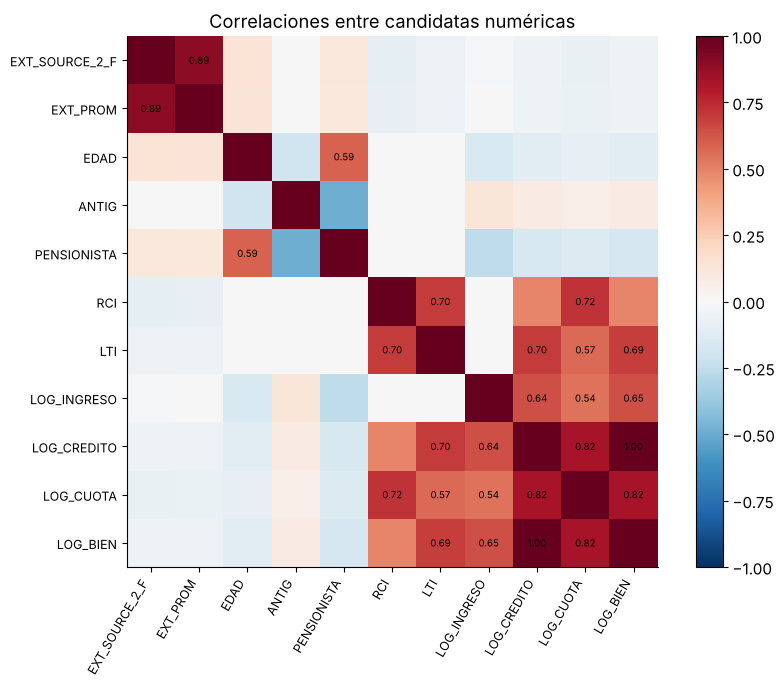

Número de condición (estandarizado): 40.9


,VIF
LOG_BIEN,205.2
LOG_CREDITO,204.5
LOG_CUOTA,9.0
LTI,8.4
RCI,5.7
LOG_INGRESO,5.3
EXT_SOURCE_2_F,4.9
EXT_PROM,4.9
PENSIONISTA,2.0
EDAD,1.6


In [2]:
num = ["EXT_SOURCE_2_F", "EXT_PROM", "EDAD", "ANTIG", "PENSIONISTA", "RCI", "LTI", "LOG_INGRESO", "LOG_CREDITO", "LOG_CUOTA", "LOG_BIEN"]
corr = dev[num].corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); ax.set_xticks(range(len(num))); ax.set_xticklabels(num, rotation=60, ha="right", fontsize=9)
ax.set_yticks(range(len(num))); ax.set_yticklabels(num, fontsize=9); ax.grid(False)
for i in range(len(num)):
    for j in range(len(num)):
        if abs(corr.values[i, j]) > 0.5 and i != j: ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im); plt.title("Correlaciones entre candidatas numéricas"); plt.tight_layout(); plt.show()

Xv = sm.add_constant(StandardScaler().fit_transform(dev[num]))
vif = pd.Series([variance_inflation_factor(Xv, i) for i in range(1, Xv.shape[1])], index=num).sort_values(ascending=False)
print(f"Número de condición (estandarizado): {np.linalg.cond(Xv):.1f}")
vif.to_frame("VIF").style.format("{:.1f}").map(lambda v: "background-color:#f8d7da" if v > 10 else ("background-color:#fff4d6" if v > 5 else ""))

**Lectura:** `LOG_CREDITO`, `LOG_BIEN` y `LOG_CUOTA` son casi la misma información (el monto del crédito); `RCI` y `LTI` se construyen con ellas y con el ingreso. `EXT_PROM` es un promedio que incluye `EXT_SOURCE_2`.

### Consecuencia: coeficientes inestables
Estimemos el mismo modelo en 200 muestras bootstrap, con y sin las variables redundantes.

In [3]:
rng = np.random.default_rng(0)
def boot_coefs(cols, B=200, n=8000):
    out = []
    for _ in range(B):
        s = dev.sample(n, replace=True, random_state=int(rng.integers(1e9)))
        out.append(sm.Logit(s.TARGET, sm.add_constant(s[cols])).fit(disp=0).params[cols])
    return pd.DataFrame(out)
con = boot_coefs(["EXT_SOURCE_2_F", "EXT_PROM", "LOG_CREDITO", "LOG_BIEN", "LOG_CUOTA", "LOG_INGRESO"])
sin = boot_coefs(["EXT_PROM", "LOG_CREDITO", "LOG_INGRESO"])
res = pd.DataFrame({"media (con redundantes)": con.mean(), "desv. (con redundantes)": con.std(), "% signo negativo (con)": (con < 0).mean(),
                    "media (sin)": sin.mean(), "desv. (sin)": sin.std()})
res.style.format({c: "{:.3f}" for c in res.columns if "%" not in c} | {"% signo negativo (con)": "{:.0%}"})

,media (con redundantes),desv. (con redundantes),% signo negativo (con),media (sin),desv. (sin)
EXT_PROM,-4.448,0.632,100%,-5.301,0.274
EXT_SOURCE_2_F,-0.839,0.531,95%,nan,nan
LOG_BIEN,-0.785,0.772,84%,nan,nan
LOG_CREDITO,0.779,0.776,16%,0.255,0.068
LOG_CUOTA,0.253,0.073,0%,nan,nan
LOG_INGRESO,-0.274,0.104,100%,-0.285,0.104


**Lectura:** con variables redundantes, los coeficientes de los montos tienen desviaciones varias veces mayores y su **signo cambia** entre muestras. El modelo predice igual, pero ningún comité aprobaría un scorecard donde "más monto" a veces suma y a veces resta riesgo. Remedios: eliminar redundantes (criterio de negocio + VIF), combinarlas en ratios (RCI), usar regularización o trabajar con WoE (sesión 3).

## 2. Regularización L1, L2 y elastic net
Maximizamos una log-verosimilitud **penalizada**:
$$\max_\beta \; \ell(\beta) - \lambda\left[\alpha \|\beta\|_1 + \tfrac{1-\alpha}{2}\|\beta\|_2^2\right], \qquad C = 1/\lambda \text{ en scikit-learn}$$

| Penalización | Efecto | Uso típico |
|---|---|---|
| **L2 (ridge)**, α = 0 | Encoge todos los coeficientes, no los anula | Multicolinealidad, estabilidad |
| **L1 (lasso)**, α = 1 | Anula coeficientes: **selecciona variables** | Selección con muchas candidatas |
| **Elastic net**, 0 < α < 1 | Selecciona y reparte el peso entre variables correlacionadas | Grupos de variables correlacionadas |

> Las variables deben **estandarizarse** antes de penalizar; si no, la penalización depende de las unidades.

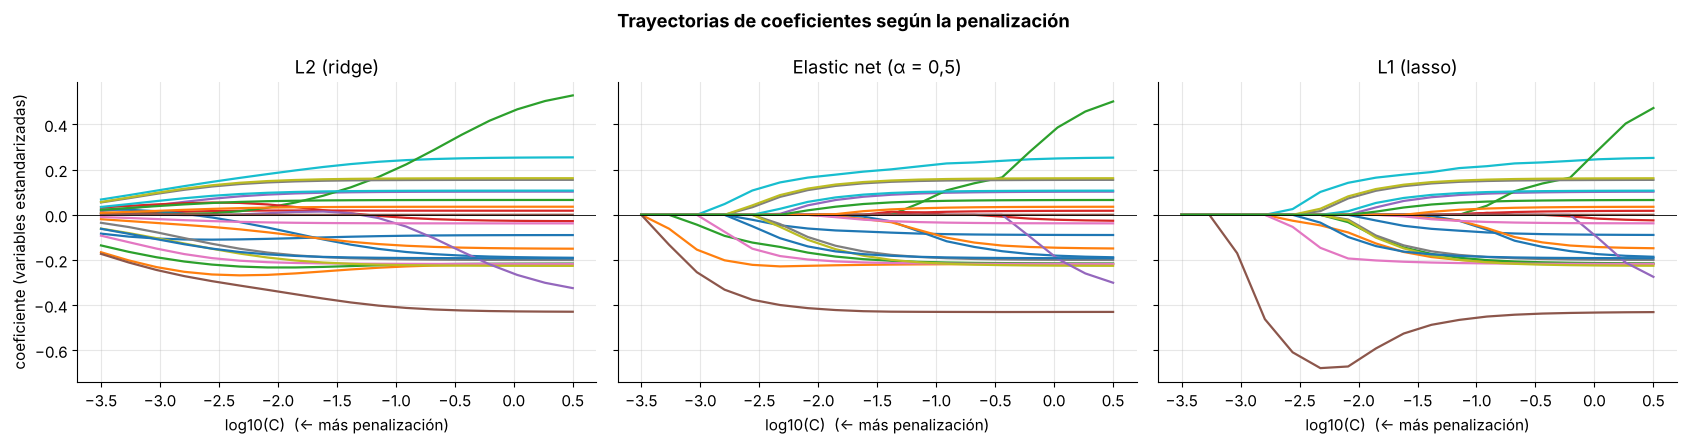

In [4]:
sub = dev.sample(20000, random_state=1)
Xs = StandardScaler().fit_transform(sub[CANDIDATAS]); ys = sub.TARGET.values
Cs = np.logspace(-3.5, 0.5, 18)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for a, (nombre, l1r) in zip(ax, [("L2 (ridge)", 0.0), ("Elastic net (α = 0,5)", 0.5), ("L1 (lasso)", 1.0)]):
    path = np.array([logit_pen(C, l1r).fit(Xs, ys).coef_[0] for C in Cs])
    for j in range(path.shape[1]):
        a.plot(np.log10(Cs), path[:, j], lw=1.6)
    a.axhline(0, color="black", lw=.6); a.set_title(nombre); a.set_xlabel("log10(C)  (← más penalización)")
ax[0].set_ylabel("coeficiente (variables estandarizadas)")
plt.suptitle("Trayectorias de coeficientes según la penalización", weight="bold"); plt.tight_layout(); plt.show()

Mejor combinación por log-loss de validación cruzada: l1_ratio = 0.5, C = 0.0316, log-loss = 0.25230


Variables con coeficiente distinto de cero: 21 de 23
AUC fuera de tiempo: 0.7703


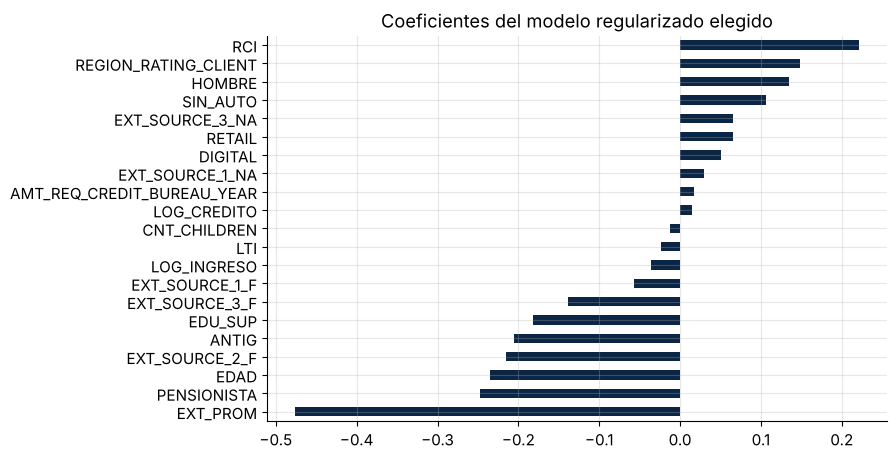

In [5]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
cv = StratifiedKFold(5, shuffle=True, random_state=0)
grid = []
for l1r in [0.0, 0.5, 1.0]:
    for C in np.logspace(-3, 0.5, 8):
        sc = cross_val_score(make_pipeline(StandardScaler(), logit_pen(C, l1r)), sub[CANDIDATAS], ys, cv=cv, scoring="neg_log_loss").mean()
        grid.append((l1r, C, -sc))
g = pd.DataFrame(grid, columns=["l1_ratio", "C", "logloss_cv"])
best = g.loc[g.logloss_cv.idxmin()]
print(f"Mejor combinación por log-loss de validación cruzada: l1_ratio = {best.l1_ratio}, C = {best.C:.4f}, log-loss = {best.logloss_cv:.5f}")
mejor = make_pipeline(StandardScaler(), logit_pen(best.C, best.l1_ratio)).fit(dev[CANDIDATAS], dev.TARGET)
coef = pd.Series(mejor[-1].coef_[0], index=CANDIDATAS)
print(f"Variables con coeficiente distinto de cero: {(coef.abs() > 1e-6).sum()} de {len(CANDIDATAS)}")
print(f"AUC fuera de tiempo: {roc_auc_score(oot.TARGET, mejor.predict_proba(oot[CANDIDATAS])[:, 1]):.4f}")
coef[coef.abs() > 1e-6].sort_values().plot(kind="barh", color=AZUL, figsize=(8, 5)); plt.title("Coeficientes del modelo regularizado elegido"); plt.show()

## 3. Selección de variables: cinco enfoques

| Enfoque | Ejemplo | Ventaja | Riesgo |
|---|---|---|---|
| **Criterio de negocio** | Excluir variables no explicables o prohibidas | Interpretabilidad, cumplimiento | Sesgo del experto |
| **Filtro** | IV, AUC univariado, correlación | Rápido, entendible | Ignora redundancia e interacciones |
| **Wrapper** | Stepwise forward/backward con AIC/BIC | Considera el modelo conjunto | Inestable, sobreajuste, p-valores sesgados |
| **Embebido** | L1 / elastic net | Selección y estimación a la vez | Elige una al azar entre correlacionadas |
| **Estabilidad** | Stability selection (L1 + bootstrap) | Robusto, controla falsos positivos | Costo computacional |

> **Regla de oro:** toda selección se hace **solo con datos de desarrollo**. Seleccionar con todos los datos y luego validar infla el desempeño (fuga de información).

In [6]:
# (a) Filtro: AUC univariado (como Gini) y correlación con la variable objetivo
filtro = pd.DataFrame({"gini_univariado": [abs(2 * roc_auc_score(dev.TARGET, dev[c]) - 1) for c in CANDIDATAS]}, index=CANDIDATAS)
filtro = filtro.sort_values("gini_univariado", ascending=False)

# (b) Wrapper: forward stepwise con AIC y BIC (statsmodels)
def forward_stepwise(df, y, cands, criterio="aic", max_vars=15):
    sel, actual = [], np.inf
    while len(sel) < max_vars:
        mejores = []
        for c in [c for c in cands if c not in sel]:
            m = sm.Logit(y, sm.add_constant(df[sel + [c]])).fit(disp=0)
            mejores.append((getattr(m, criterio), c))
        val, c = min(mejores)
        if val >= actual: break
        sel.append(c); actual = val
    return sel
step_aic = forward_stepwise(dev, dev.TARGET, CANDIDATAS, "aic")
step_bic = forward_stepwise(dev, dev.TARGET, CANDIDATAS, "bic")
print("Stepwise AIC:", step_aic); print("Stepwise BIC:", step_bic)

Stepwise AIC: ['EXT_PROM', 'EDAD', 'RCI', 'EDU_SUP', 'REGION_RATING_CLIENT', 'HOMBRE', 'ANTIG', 'PENSIONISTA', 'SIN_AUTO', 'RETAIL', 'EXT_SOURCE_3_NA', 'DIGITAL', 'EXT_SOURCE_2_F', 'EXT_SOURCE_3_F', 'EXT_SOURCE_1_F']
Stepwise BIC: ['EXT_PROM', 'EDAD', 'RCI', 'EDU_SUP', 'REGION_RATING_CLIENT', 'HOMBRE', 'ANTIG', 'PENSIONISTA', 'SIN_AUTO', 'RETAIL', 'EXT_SOURCE_3_NA']


In [7]:
# (c) Stability selection: frecuencia de selección de L1 en 60 submuestras de la mitad de los datos
from sklearn.preprocessing import StandardScaler
rng = np.random.default_rng(42); B = 60; frec = np.zeros(len(CANDIDATAS))
Xd = StandardScaler().fit_transform(dev[CANDIDATAS]); yd = dev.TARGET.values
for _ in range(B):
    idx = rng.choice(len(yd), len(yd) // 2, replace=False)
    m = logit_pen(C=0.01, l1_ratio=1.0).fit(Xd[idx], yd[idx])
    frec += (np.abs(m.coef_[0]) > 1e-6)
estab = pd.Series(frec / B, index=CANDIDATAS)

# (d) Importancia por permutación (en fuera de tiempo, modelo con todas las candidatas)
full = make_pipeline(StandardScaler(), logit_pen(C=1.0, l1_ratio=0.0)).fit(dev[CANDIDATAS], dev.TARGET)
pi = permutation_importance(full, oot[CANDIDATAS], oot.TARGET, scoring="roc_auc", n_repeats=5, random_state=0)
perm = pd.Series(pi.importances_mean, index=CANDIDATAS)

comp = filtro.join(pd.DataFrame({"stepwise_AIC": [c in step_aic for c in CANDIDATAS], "stepwise_BIC": [c in step_bic for c in CANDIDATAS],
                                 "L1_elegido": (coef.abs() > 1e-6).values, "estabilidad_L1": estab.values, "perm_ΔAUC": perm.values}, index=CANDIDATAS))
comp.style.format({"gini_univariado": "{:.3f}", "estabilidad_L1": "{:.0%}", "perm_ΔAUC": "{:.4f}"}).background_gradient(subset=["estabilidad_L1"], cmap="Greens")

,gini_univariado,stepwise_AIC,stepwise_BIC,L1_elegido,estabilidad_L1,perm_ΔAUC
EXT_PROM,0.460,True,True,True,100%,0.0570
EXT_SOURCE_2_F,0.433,True,False,True,100%,0.0070
EXT_SOURCE_3_F,0.356,True,False,True,72%,0.0043
EDAD,0.227,True,True,True,100%,0.0080
EXT_SOURCE_1_F,0.194,True,False,True,8%,-0.0001
RCI,0.139,True,True,True,100%,0.0162
LTI,0.114,False,False,True,2%,0.0015
LOG_CUOTA,0.113,False,False,False,0%,-0.0005
PENSIONISTA,0.109,True,True,True,100%,0.0112
EDU_SUP,0.088,True,True,True,100%,0.0079


In [8]:
def evaluar(cols, nombre):
    m = sm.Logit(dev.TARGET, sm.add_constant(dev[cols])).fit(disp=0)
    p = m.predict(sm.add_constant(oot[cols]))
    return {"modelo": nombre, "n_vars": len(cols), "AIC_dev": m.aic, "AUC_oot": roc_auc_score(oot.TARGET, p), "logloss_oot": log_loss(oot.TARGET, p)}
estables = estab[estab >= 0.8].index.tolist()
top_filtro = filtro.index[:8].tolist()
pd.DataFrame([evaluar(CANDIDATAS, "Todas"), evaluar(top_filtro, "Top 8 por Gini univariado"), evaluar(step_aic, "Stepwise AIC"),
              evaluar(step_bic, "Stepwise BIC"), evaluar(estables, "Stability selection (≥ 80 %)")]).set_index("modelo").style.format(
    {"AIC_dev": "{:,.1f}", "AUC_oot": "{:.4f}", "logloss_oot": "{:.5f}"})

,n_vars,AIC_dev,AUC_oot,logloss_oot
modelo,,,,
Todas,23,"23,034.9",0.7700,0.19809
Top 8 por Gini univariado,8,"23,467.6",0.7575,0.20097
Stepwise AIC,15,"23,041.5",0.7708,0.19789
Stepwise BIC,11,"23,064.3",0.7710,0.19798
Stability selection (≥ 80 %),10,"23,077.6",0.7707,0.19804


**Ojo con la importancia por permutación en presencia de colinealidad:** `LOG_CREDITO` aparece como la variable "más importante" del modelo completo porque, al permutarla, se rompe el equilibrio con su gemela `LOG_BIEN` (coeficientes grandes y de signo opuesto). Es un artefacto de la multicolinealidad, no información real.

## 4. Métodos avanzados para modelos logísticos
### 4.1 No linealidades con splines
Un **spline** (polinomios por tramos unidos suavemente) permite que el log-odds tenga cualquier forma sin perder la estructura logística. Probemos en dos variables: `RCI` (no linealidad leve, según el logit empírico de la sesión 1) y `EXT_SOURCE_2` (relación en forma de logit: más pronunciada en los extremos).

,AUC_oot,logloss_oot
modelo,,
Todo lineal,0.7550,0.20133
Spline en RCI,0.7543,0.20152
Spline en EXT_SOURCE_2_F,0.7561,0.20098


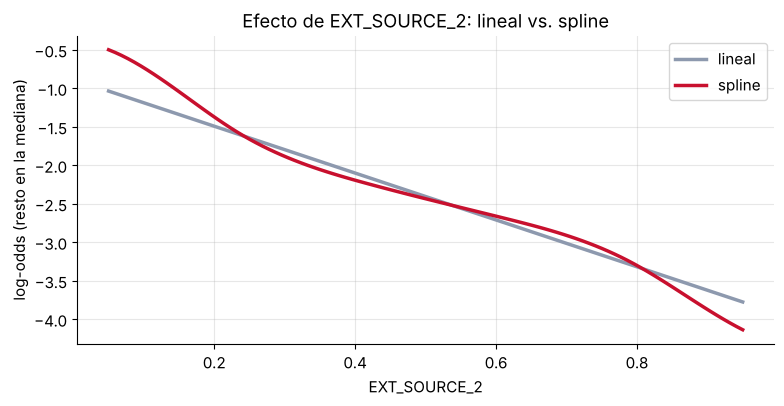

In [9]:
from sklearn.compose import ColumnTransformer
base = ["EXT_SOURCE_2_F", "EXT_SOURCE_3_F", "EXT_SOURCE_3_NA", "EDAD", "PENSIONISTA", "RCI", "ANTIG"]
dev_c = dev.assign(RCI=dev.RCI.clip(upper=3)); oot_c = oot.assign(RCI=oot.RCI.clip(upper=3))
def modelo(var_spline=None):
    otras = [b for b in base if b != var_spline]
    pasos = [("num", StandardScaler(), otras)]
    if var_spline: pasos.append(("spl", SplineTransformer(n_knots=6, degree=3, extrapolation="constant"), [var_spline]))
    return make_pipeline(ColumnTransformer(pasos), logit_pen(C=10)).fit(dev_c, dev_c.TARGET)
res, mods = [], {}
for v in [None, "RCI", "EXT_SOURCE_2_F"]:
    mods[v] = modelo(v); p_ = mods[v].predict_proba(oot_c)[:, 1]
    res.append({"modelo": "Todo lineal" if v is None else f"Spline en {v}", "AUC_oot": roc_auc_score(oot_c.TARGET, p_), "logloss_oot": log_loss(oot_c.TARGET, p_)})
display(pd.DataFrame(res).set_index("modelo").style.format({"AUC_oot": "{:.4f}", "logloss_oot": "{:.5f}"}))
grid_e = np.linspace(0.05, 0.95, 100)
perfil = pd.DataFrame({c: [dev_c[c].median()] * 100 for c in base}).assign(EXT_SOURCE_2_F=grid_e)
plt.figure(figsize=(9, 4))
for nombre, v, col in [("lineal", None, GRIS), ("spline", "EXT_SOURCE_2_F", ROJO)]:
    pp = mods[v].predict_proba(perfil)[:, 1]; plt.plot(grid_e, np.log(pp / (1 - pp)), color=col, lw=2.5, label=nombre)
plt.xlabel("EXT_SOURCE_2"); plt.ylabel("log-odds (resto en la mediana)"); plt.legend(); plt.title("Efecto de EXT_SOURCE_2: lineal vs. spline"); plt.show()

**Lectura:** el spline mejora `EXT_SOURCE_2`, cuyo efecto se acelera en los extremos, y **no** mejora `RCI`, cuya no linealidad es leve y ruidosa. Lección: agrega flexibilidad solo donde la evidencia fuera de tiempo lo justifica. Cada grado de libertad extra es algo más que monitorear y explicar.

### 4.2 Interacciones
Una interacción permite que el efecto de una variable dependa de otra. Ejemplo: ¿el efecto de `EXT_SOURCE_2` es distinto en el canal digital? Se contrasta con un test de razón de verosimilitud (Módulo 2).

In [10]:
from scipy import stats
d2 = dev.assign(EXT2_x_DIGITAL=dev.EXT_SOURCE_2_F * dev.DIGITAL)
m0 = sm.Logit(d2.TARGET, sm.add_constant(d2[["EXT_SOURCE_2_F", "DIGITAL", "EDAD"]])).fit(disp=0)
m1 = sm.Logit(d2.TARGET, sm.add_constant(d2[["EXT_SOURCE_2_F", "DIGITAL", "EDAD", "EXT2_x_DIGITAL"]])).fit(disp=0)
LR = 2 * (m1.llf - m0.llf)
print(m1.params.round(3).to_string()); print(f"\nLR = {LR:.2f}, p-valor = {stats.chi2.sf(LR, 1):.4f}")

const             0.8670
EXT_SOURCE_2_F   -4.1480
DIGITAL           0.1450
EDAD             -0.0230
EXT2_x_DIGITAL   -0.1090

LR = 0.26, p-valor = 0.6135


**Lectura:** la interacción no es significativa (p ≈ 0,6): el efecto de `EXT_SOURCE_2` es el mismo en el canal digital, así que no se incluye. Probar interacciones "a ciegas" infla el riesgo de falsos positivos; conviene partir de hipótesis de negocio (o de las interacciones que detecten los árboles, Módulo 4).

### 4.3 Otros métodos avanzados (panorama)

| Método | Idea | Cuándo |
|---|---|---|
| **Firth** (sesión 1) | Verosimilitud penalizada con el prior de Jeffreys | Eventos raros, separación |
| **Modelos segmentados** | Un scorecard por segmento (nuevos/recurrentes, producto) | Poblaciones con comportamientos distintos |
| **GAM / splines** | Log-odds aditivo y no lineal | No linealidades fuertes con interpretabilidad |
| **WoE + logística** (sesión 3) | Discretización óptima con monotonicidad | Estándar de la industria para scorecards |
| **Logística bayesiana** (Módulo 6) | Priors sobre los coeficientes | Poca data, conocimiento experto |
| **Restricciones de signo** | Coeficientes con el signo esperado | Requisito regulatorio o de negocio |
| **Reject inference** | Incorporar a los rechazados | Sesgo de selección en originación |

## 5. Ejercicios
1. Elimina las variables con VIF > 10 y vuelve a estimar. ¿Se estabilizan los signos en el bootstrap?
2. Repite la stability selection con C = 0,005 y C = 0,05. ¿Cómo cambia el conjunto estable?
3. Agrega un spline a `EDAD`. ¿Mejora el log-loss fuera de tiempo?
4. Estima modelos separados para pensionistas y no pensionistas. ¿Cambian los coeficientes de `EXT_SOURCE_2`?